In [1]:
# This is a companion notebook to "Oracle-centric perspective on structured quantum search applied
# to lattice sieving" (Kavalaris, Mardiris, Karafyllidis).
# This companion runs either on Jupyter Notebook or Google Colab. It needs Qiskit to be installed.
# It was tested with Qiskit 2.6.1.

# In this example, the sieving predicate is realized as a local oracle, a marked coin that acts only
# at the reducible pairs, composed with every step of a quantum walk on the Johnson graph J(6,2), as
# described in Section 5 of the paper. The sieve list, the predicate and the candidate pairs are the
# same as in the companion notebook of the Grover realization (Section 4), so the two examples
# realize the same predicate on the same instance and differ only in how the oracle is realized. The
# walk is run with and without the oracle on a simulator.

# The code that builds the instance (Cells 4 and 5) is repeated here with short comments only, so
# that the notebook runs on its own. It is explained in full in the Grover notebook.

In [2]:
# The line below is used the first time to install Qiskit and pylatexenc if they are not already
# installed. pylatexenc is used by Qiskit to draw circuits. The line is commented out, so if you do
# not have these libraries installed, remove the # from the line below. This is definitely needed
# in Google Colab.
# %pip install qiskit pylatexenc

In [3]:
# Load the needed libraries

import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation, UnitaryGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.primitives import StatevectorSampler

# Needed in Jupyter notebooks so that plots appear below the cells that create them
%matplotlib inline

# Print the used versions. This example was created with Qiskit 2.6.1
print("qiskit", qiskit.__version__, "| numpy", np.__version__)

qiskit 2.6.1 | numpy 2.4.6


In [4]:
# The code of this cell is identical to Cells 5 and 6 of the companion notebook of the Grover
# realization (Example 1), where every parameter and function is explained. It is repeated here only
# so that this notebook runs on its own.

SEED = 20251006           # seed of NumPy's pseudo-random number generator
DIM = 10                  # vectors of the lattice Z^DIM
LIST_SIZE = 6             # sieve list L_list = {v1, ..., v6}, with 6 * 5 / 2 = 15 pairs
COORD_RANGE = 3           # coordinates drawn uniformly from -3..3
NORM2_TARGET = 4 * DIM    # centre of the norm shell (squared norm 40)
NORM2_WIDTH = 2           # keep vectors with 38 <= ||v||^2 <= 42

# The function sieve_list(seed) returns a random sieve list of LIST_SIZE vectors of Z^DIM from the
# norm shell, distinct up to sign.
def sieve_list(seed):
    rng = np.random.default_rng(seed)
    vectors = []
    while len(vectors) < LIST_SIZE:
        v = rng.integers(-COORD_RANGE, COORD_RANGE + 1, size=DIM, dtype=np.int64)
        if abs(int(v @ v) - NORM2_TARGET) > NORM2_WIDTH:
            continue                        # outside the norm shell
        if any((v == u).all() or (v == -u).all() for u in vectors):
            continue                        # already in the list, up to sign
        vectors.append(v)
    return vectors

# The function is_reducible(u, w) returns True if u - w or u + w is shorter than the longer of u and
# w. This is the sieving predicate of Eq. (11), evaluated on squared norms, which are exact
# integers.
def is_reducible(u, w):
    longest2 = max(int(u @ u), int(w @ w))
    return int((u - w) @ (u - w)) < longest2 or int((u + w) @ (u + w)) < longest2

# The function candidate_pairs() returns the 15 pairs (i, j), i < j, in lexicographic order.
# Positions are 0-based, so (0, 1) is (v1, v2), with index 0.
def candidate_pairs():
    return list(itertools.combinations(range(LIST_SIZE), 2))

# The function marked_pairs(vectors) returns the marked set M = f^-1(1) of Eq. (14), that is, the
# indices of the reducible pairs.
def marked_pairs(vectors):
    return [k for k, (i, j) in enumerate(candidate_pairs())
            if is_reducible(vectors[i], vectors[j])]

# The function pair_label(k) returns pair index k as written in the paper, e.g. 13 -> '(v4, v6)'.
def pair_label(k):
    i, j = candidate_pairs()[k]
    return f"(v{i + 1}, v{j + 1})"

In [5]:
# This cell builds the sieve list of the example with SEED, evaluates the sieving predicate on all
# 15 candidate pairs and prints the result. The printed list and reducible pairs are the same as in
# the Grover notebook, which confirms that both examples act on the same instance. Squared norms are
# printed, because they are exact integers. (same as Cell 7 of Example 1)

vectors = sieve_list(SEED)
pairs = candidate_pairs()
M = marked_pairs(vectors)

# If the list has no reducible pair there is nothing to search for, so the example stops here
# with an explanation instead of failing later.
if len(M) == 0:
    raise SystemExit("This seed gives no reducible pair, so there is nothing "
                     "to search for. Please choose another SEED.")

print(f"Sieve list: {LIST_SIZE} vectors of Z^{DIM} (SEED = {SEED})")
for i, v in enumerate(vectors):
    print(f"  v{i + 1} = {tuple(int(c) for c in v)}   ||v{i + 1}||^2 = {int(v @ v)}")

print(f"\n{len(pairs)} candidate pairs; reducible pairs (marked set M):")
for k in M:
    i, j = pairs[k]
    longest2 = max(int(vectors[i] @ vectors[i]), int(vectors[j] @ vectors[j]))
    diff2 = int((vectors[i] - vectors[j]) @ (vectors[i] - vectors[j]))
    sum2 = int((vectors[i] + vectors[j]) @ (vectors[i] + vectors[j]))
    if diff2 < longest2:
        reason = f"||v{i + 1} - v{j + 1}||^2 = {diff2}"
    else:
        reason = f"||v{i + 1} + v{j + 1}||^2 = {sum2}"
    print(f"  index {k}: {pair_label(k)}, {reason} < {longest2} = larger squared norm")
print(f"\n|M| = {len(M)} marked pairs out of {len(pairs)}")

Sieve list: 6 vectors of Z^10 (SEED = 20251006)
  v1 = (-3, -3, -1, 0, 3, 0, -3, -2, -1, 0)   ||v1||^2 = 42
  v2 = (3, -2, 1, 0, 3, 0, 2, 2, 0, 3)   ||v2||^2 = 40
  v3 = (2, -1, 2, 2, -3, 0, 2, -3, 1, -2)   ||v3||^2 = 40
  v4 = (3, 2, 1, -1, 0, -3, -1, 3, -2, 1)   ||v4||^2 = 39
  v5 = (-2, -2, 2, -3, -3, 1, 0, -3, 0, -1)   ||v5||^2 = 41
  v6 = (-3, -1, 3, 0, -1, 3, 3, -1, 1, 1)   ||v6||^2 = 41

15 candidate pairs; reducible pairs (marked set M):
  index 13: (v4, v6), ||v4 + v6||^2 = 32 < 41 = larger squared norm
  index 14: (v5, v6), ||v5 - v6||^2 = 38 < 41 = larger squared norm

|M| = 2 marked pairs out of 15


In [6]:
# The quantum walk of Section 5 moves on a graph whose vertices are subsets of the sieve list
# (Section 5.1). Here the subsets are the candidate pairs themselves. The vertices of the Johnson
# graph J(6,2) are the 15 pairs {v_i, v_j}, and two pairs are adjacent (connected by an edge) when
# they share exactly one vector. For example, (v1, v2) is adjacent to (v1, v3), because they share
# v1, but not to (v3, v4). Every pair is adjacent to 2 * (6 - 2) = 8 others, because one of its two
# vectors is kept and the other is replaced by one of the 4 vectors not in the pair.

# In relation to the literature, Chailloux and Loyer [6] walk on Johnson graphs whose vertices are
# larger subsets of a filtered list, combined with locality-sensitive filtering. This example uses
# subsets of two vectors, the simplest case, in which a vertex is a single pair. It uses their graph
# family but does not reproduce their algorithm.

# The spectral gap is defined through the classical random walk on the graph, which moves at each
# step to a uniformly chosen neighbour. The transition matrix of this walk has largest eigenvalue 1.
# The spectral gap delta is 1 minus the second largest eigenvalue, and it measures how quickly the
# walk spreads over the whole graph. Delta appears in the cost of quantum-walk search, Eq. (16). The
# larger delta, the fewer walk steps are needed. The cell computes delta for J(6,2).


# The function johnson_neighbours() returns, for every pair index u = 0..14, the sorted list of the
# indices of the 8 pairs adjacent to u in J(6,2).
def johnson_neighbours():
    index = {pair: k for k, pair in enumerate(candidate_pairs())}
    neighbours = []
    for pair in candidate_pairs():
        adjacent = []
        for drop in pair:                                   # vector replaced
            keep = pair[0] if drop == pair[1] else pair[1]  # vector kept
            for new in range(LIST_SIZE):
                if new not in pair:
                    adjacent.append(index[tuple(sorted((keep, new)))])
        neighbours.append(sorted(adjacent))
    return neighbours


nbrs = johnson_neighbours()
NUM_VERTICES = len(nbrs)           # 15
DEGREE = len(nbrs[0])              # 8

for k in M:
    print(f"{pair_label(k)} is adjacent to "
          + ", ".join(pair_label(u) for u in nbrs[k]))

transition = np.zeros((NUM_VERTICES, NUM_VERTICES))
for u in range(NUM_VERTICES):
    for v in nbrs[u]:
        transition[v, u] = 1 / DEGREE
eigenvalues = np.sort(np.linalg.eigvalsh(transition))[::-1]
print(f"\n{NUM_VERTICES} vertices, each with {DEGREE} neighbours")
distinct = sorted({round(float(e), 6) for e in eigenvalues}, reverse=True)
print("distinct eigenvalues of the transition matrix:",
      ", ".join(f"{e:g}" for e in distinct))
print(f"spectral gap delta = 1 - {eigenvalues[1]:.2f} = {1 - eigenvalues[1]:.2f}")

(v4, v6) is adjacent to (v1, v4), (v1, v6), (v2, v4), (v2, v6), (v3, v4), (v3, v6), (v4, v5), (v5, v6)
(v5, v6) is adjacent to (v1, v5), (v1, v6), (v2, v5), (v2, v6), (v3, v5), (v3, v6), (v4, v5), (v4, v6)

15 vertices, each with 8 neighbours
distinct eigenvalues of the transition matrix: 1, 0.25, -0.25
spectral gap delta = 1 - 0.25 = 0.75


In [7]:
# This cell only defines functions and nothing is computed yet. Together they build a coined quantum
# walk on J(6,2) in which the sieving predicate acts as a local oracle, following the coined
# quantum-walk search of Shenvi, Kempe and Whaley and of Ambainis, Kempe and Rivosh [25, 26].
# Eq. (9) of the paper gives the general form U = S (C x I) of a coined walk.

# The coin. At every vertex the walker carries a coin state that says along which of the 8 edges it
# moves next. The coin space is spanned by these 8 directions, and |s_c> is their uniform
# superposition. The walk is defined as follows.
#     Grover coin   G   = 2 |s_c><s_c| - I              (acts on the 8 directions)
#     marked coin   C'  = G at unmarked pairs,  -I at marked pairs
#     shift         S   sends the walker at u, moving towards v, to v,
#                         facing back towards u              ("flip-flop" shift)
#     walk step     U'  = S C'
#     start         |s_c> on the coin, uniform superposition over the 15 pairs
# In the paper, C' and U' are Eqs. (18) and (19).

# The oracle. The predicate enters only through C'. At a reducible pair the Grover coin is replaced
# by -I, so the marking acts locally, at the marked vertices only, and is composed with every step
# of the walk. This corresponds to the local marking discussed in Section 5.2 (Eqs. (13) to (15)),
# since two steps of this coined walk equal one step of Szegedy's walk in which the marked vertices
# are absorbing [18].

# The encoding. Qubits 0, 1, 2 hold the coin, that is, the direction k = 0..7, meaning the k-th
# neighbour in the sorted list of the current pair. Qubits 3, 4, 5, 6 hold the pair index u = 0..14
# in binary. The state |k, u> therefore has basis index k + 8u. Index 15 of the pair register
# corresponds to no pair and is never populated.

# The circuits. C' is built from Hadamard, X and multi-controlled phase gates, with one
# multi-controlled phase gate per reducible pair, as in the Grover realization. The circuit gives C'
# up to a global phase, which has no effect on any measured probability, and Cell 9 checks that it
# is correct. The shift S depends only on the shape of the graph. It is a fixed rearrangement
# (permutation) of the basis states |k, u>, built here as a 128 x 128 permutation matrix and passed
# to Qiskit as one gate, which Qiskit translates into elementary gates when needed (see Cell 14).

N_COIN = 3                          # 2^3 = 8 directions
N_POS = 4                           # 2^4 = 16 >= 15 pair indices
N_WALK_QUBITS = N_COIN + N_POS      # 7
COIN = list(range(N_COIN))          # qubits 0, 1, 2
POS = list(range(N_COIN, N_WALK_QUBITS))   # qubits 3, 4, 5, 6


# The function prepare_initial_state(qc) prepares the start of the walk, that is, the uniform coin
# state |s_c> (Hadamard gates on the coin qubits) and the uniform superposition over the 15 pairs on
# the pair register (StatePreparation, which leaves the padding index 15 empty).
def prepare_initial_state(qc):
    qc.h(COIN)
    amplitudes = np.zeros(2 ** N_POS)
    amplitudes[:NUM_VERTICES] = 1 / np.sqrt(NUM_VERTICES)
    qc.append(StatePreparation(amplitudes), POS)


# The function apply_marked_coin(qc, marked) applies the marked coin C', which is the local oracle.
def apply_marked_coin(qc, marked):
    c0, c1, c2 = COIN
    qc.h(COIN)
    qc.x(COIN)
    qc.mcp(np.pi, [c0, c1], c2)                     # CCZ on the coin
    for m in marked:                                # CCZ_m for each marked pair
        zeros = [POS[b] for b in range(N_POS) if not (m >> b) & 1]
        if zeros:
            qc.x(zeros)
        qc.mcp(np.pi, [c0, c1] + POS, c2)
        if zeros:
            qc.x(zeros)
    qc.x(COIN)
    qc.h(COIN)


# The function shift_matrix() returns the flip-flop shift S as a permutation matrix. The basis state
# |k, u> (walker at u, facing its k-th neighbour v) is sent to |k', v>, where k' is the position of
# u in the neighbour list of v. The padding index 15 is left unchanged.
def shift_matrix():
    dim = 2 ** N_WALK_QUBITS
    P = np.zeros((dim, dim))
    for u in range(2 ** N_POS):
        for k in range(DEGREE):
            old = k + DEGREE * u
            if u < NUM_VERTICES:
                v = nbrs[u][k]
                new = nbrs[v].index(u) + DEGREE * v
            else:
                new = old
            P[new, old] = 1
    return P


SHIFT_GATE = UnitaryGate(shift_matrix(), label="S")

# The function walk_step(qc, marked) applies one walk step U' = S C'.
def walk_step(qc, marked):
    apply_marked_coin(qc, marked)
    qc.append(SHIFT_GATE, COIN + POS)

# The function walk_circuit(marked, steps, measure) builds the full circuit, that is, the initial
# state followed by `steps` walk steps. With marked = [] the oracle is left out and the coin is the
# Grover coin everywhere. This is the control used to show what the oracle contributes. With
# measure=True, all qubits are measured at the end.
def walk_circuit(marked, steps, measure=False):
    qc = QuantumCircuit(N_WALK_QUBITS)
    prepare_initial_state(qc)
    qc.barrier()
    for _ in range(steps):
        walk_step(qc, marked)
        qc.barrier()
    if measure:
        qc.measure_all()
    return qc

# The function pair_probabilities(state) returns the probability of finding the walker at each of
# the 15 pairs, summed over the 8 coin directions.
def pair_probabilities(state):
    p = state.probabilities().reshape(2 ** N_POS, DEGREE).sum(axis=1)
    return p[:NUM_VERTICES]

# The function walk_trace(marked, steps, probe) returns the probability of measuring a pair in
# `probe` after 0, 1, ..., `steps` walk steps, computed exactly from the state vector. One walk step
# is converted once into its unitary matrix (Operator) and then applied repeatedly, which is faster
# than simulating a longer circuit for every number of steps and gives the same result.
def walk_trace(marked, steps, probe):
    qc = QuantumCircuit(N_WALK_QUBITS)
    prepare_initial_state(qc)
    state = Statevector.from_instruction(qc)
    one_step = QuantumCircuit(N_WALK_QUBITS)
    walk_step(one_step, marked)
    step_matrix = Operator(one_step)
    probabilities = [pair_probabilities(state)[probe].sum()]
    for _ in range(steps):
        state = state.evolve(step_matrix)
        probabilities.append(pair_probabilities(state)[probe].sum())
    return np.array(probabilities)

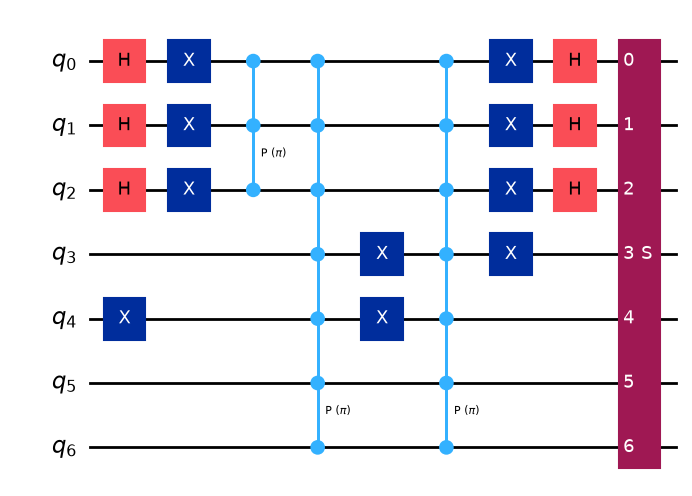

In [8]:
# This cell draws one walk step U' = S C' for the marked set of the example.

# Reading the circuit. Qubits q0..q2 hold the coin and q3..q6 the pair index, with q3 its least
# significant bit. The marked coin C' starts with Hadamard and X gates on the coin qubits and the
# controlled-controlled-Z on them, a multi-controlled phase gate P(pi) between q0, q1 and q2. Then
# follows one block per marked pair. It is the same phase gate, now also controlled by the four pair
# qubits, between X gates on the pair qubits where the index of the marked pair has a 0 bit. For
# index 13 (binary 1101) the X gates act on q4, and for index 14 (binary 1110) they act on q3.
# Qiskit draws every gate as far to the left as possible, so the first X gate on q4 appears at the
# very beginning, next to the Hadamard gates of the coin, and the X gate that closes one block
# shares a column with the X gate that opens the next. C' ends with X and Hadamard gates on the coin
# qubits, and the box S is the flip-flop shift on all seven qubits.

# The grey vertical bands are barriers that only separate the parts of the circuit in the drawing.
# They have no effect on the computation.

one_step = QuantumCircuit(N_WALK_QUBITS)
walk_step(one_step, M)
one_step.draw("mpl", fold=-1)
plt.show()

In [9]:
# The circuit of C' is not a literal transcription of its definition, because it is built from
# gates, up to a global phase. This cell checks that it is correct. It builds the walk a second
# time, directly from the definitions of the previous cells and without any quantum circuit. The
# 15 * 8 = 120 states "walker at pair u, facing its k-th neighbour" form the basis, C' is a
# block-diagonal 120 x 120 matrix with the Grover coin G at unmarked pairs and -I at marked pairs,
# and S is the 120 x 120 permutation of the flip-flop shift. Starting from the uniform state, the
# probability of every pair is computed for 20 steps with these matrices and compared with the
# circuit.

# The comparison is made for three marked sets, namely the marked set of the example, a single
# marked pair and no marked pair. The cell stops with an error if any probability differs by more
# than 1e-10.

def reference_trace(marked, steps):
    n, d = NUM_VERTICES, DEGREE
    G = 2 * np.ones((d, d)) / d - np.eye(d)
    S = np.zeros((n * d, n * d))
    C = np.zeros((n * d, n * d))
    for u in range(n):
        for k, v in enumerate(nbrs[u]):
            S[d * v + nbrs[v].index(u), d * u + k] = 1
        C[d * u:d * (u + 1), d * u:d * (u + 1)] = -np.eye(d) if u in marked else G
    U = S @ C
    psi = np.ones(n * d) / np.sqrt(n * d)
    result = []
    for _ in range(steps + 1):
        result.append((np.abs(psi) ** 2).reshape(n, d).sum(axis=1))
        psi = U @ psi
    return np.array(result)

def circuit_trace_all_pairs(marked, steps):
    qc = QuantumCircuit(N_WALK_QUBITS)
    prepare_initial_state(qc)
    state = Statevector.from_instruction(qc)
    one_step = QuantumCircuit(N_WALK_QUBITS)
    walk_step(one_step, marked)
    step_matrix = Operator(one_step)
    result = [pair_probabilities(state)]
    for _ in range(steps):
        state = state.evolve(step_matrix)
        result.append(pair_probabilities(state))
    return np.array(result)

for test_set in (M, [M[0]], []):
    deviation = np.abs(circuit_trace_all_pairs(test_set, 20)
                       - reference_trace(test_set, 20)).max()
    assert deviation < 1e-10
    print(f"marked set {[pair_label(k) for k in test_set]}: largest difference "
          f"over 20 steps = {deviation:.1e}")

marked set ['(v4, v6)', '(v5, v6)']: largest difference over 20 steps = 9.3e-15
marked set ['(v4, v6)']: largest difference over 20 steps = 8.4e-15
marked set []: largest difference over 20 steps = 1.6e-15


step   with oracle   without oracle
   0   0.133         0.133
   1   0.133         0.133
   2   0.596         0.133
   3   0.253         0.133
   4   0.486         0.133
   5   0.031         0.133
   6   0.018         0.133
   7   0.352         0.133
   8   0.212         0.133
   9   0.641         0.133
  10   0.207         0.133
  11   0.246         0.133
  12   0.056         0.133
  13   0.067         0.133
  14   0.509         0.133
  15   0.266         0.133
  16   0.605         0.133
  17   0.079         0.133
  18   0.047         0.133
  19   0.222         0.133
  20   0.152         0.133

after 2 steps: 0.596; largest value within 20 steps: 0.641 after 9 steps


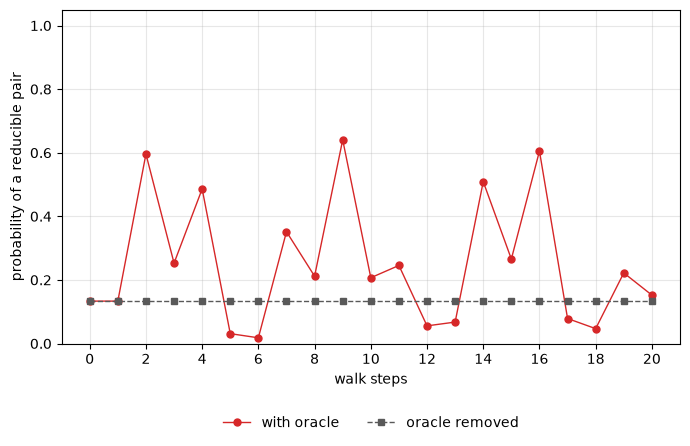

In [10]:
# This is the central result of the example. The same walk is run twice for 0, 1, ..., T_MAX steps,
# once with the marked coin C' (the oracle) and once with the oracle removed (Grover coin at every
# pair). In both runs the cell computes the exact probability of measuring one of the reducible
# pairs.

T_MAX = 20

p_with_oracle = walk_trace(M, T_MAX, probe=M)
p_without_oracle = walk_trace([], T_MAX, probe=M)
assert np.allclose(p_without_oracle, len(M) / NUM_VERTICES)

print("step   with oracle   without oracle")
for t in range(T_MAX + 1):
    print(f"{t:4d}   {p_with_oracle[t]:.3f}         {p_without_oracle[t]:.3f}")
print(f"\nafter 2 steps: {p_with_oracle[2]:.3f}; largest value within {T_MAX} steps: "
      f"{p_with_oracle.max():.3f} after {p_with_oracle.argmax()} steps")

# The plot shows the walk with the oracle as red circles joined by a line, and without the oracle as
# grey squares on a dashed line. The legend is placed below the plot so that it hides no data point.
plt.figure(figsize=(7, 4.6))
plt.plot(range(T_MAX + 1), p_with_oracle, "o-", color="C3", ms=5, lw=1,
         label="with oracle")
plt.plot(range(T_MAX + 1), p_without_oracle, "s--", color="0.35", ms=4, lw=1,
         label="oracle removed")
plt.xlabel("walk steps")
plt.ylabel("probability of a reducible pair")
plt.ylim(0, 1.05)
plt.xticks(range(0, T_MAX + 1, 2))
plt.grid(alpha=0.3)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [11]:
# Reading the result. Without the oracle, the probability stays at |M| / 15 = 2 / 15 = 0.133 for
# every number of steps. The start state (uniform over the pairs and the directions) is left
# unchanged by the unmarked walk, because the Grover coin maps |s_c> to itself and the shift maps
# the uniform state to itself. Cell 10 checks this. With the oracle, the probability rises above
# 0.133. There is no simple formula for it, as there is for Grover search. The amplitude is
# redistributed by interference along the edges of the graph, and the probability rises and falls
# irregularly. Its first maximum, 0.596, is reached after 2 steps. The largest value within 20 steps
# is 0.641, after 9 steps. The whole increase is therefore produced by the oracle.

with oracle    : 2471 of 4096 shots (0.603) return a reducible pair
oracle removed : 570 of 4096 shots (0.139) return a reducible pair


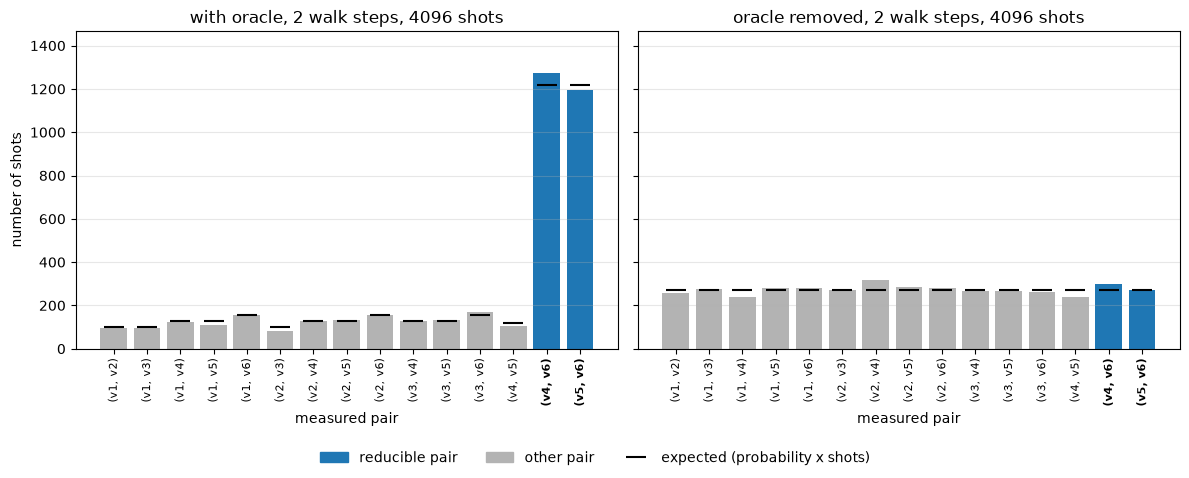

In [12]:
# Cell 10 computed exact probabilities from the state vector. A quantum computer does not give
# probabilities. Each run of the circuit ends with a measurement that returns one pair (and one coin
# direction). This cell imitates that. The walk with the oracle is stopped after STEPS = 2 steps,
# its first maximum, all qubits are measured, and the circuit is run SHOTS = 4096 times. The same is
# done with the oracle removed.

# The simulator is StatevectorSampler. It draws the measurement outcomes at random from the exact
# probabilities. Its random generator is started with SEED, so the counts below are reproducible.
# Qiskit reports each outcome as a bit string q6 q5 ... q0, whose first four bits (q6..q3) are the
# pair index.

STEPS = 2
SHOTS = 4096

sampler = StatevectorSampler(seed=SEED)
panels = []
for title, marked in (("with oracle", M), ("oracle removed", [])):
    qc = walk_circuit(marked, STEPS, measure=True)
    counts = sampler.run([qc], shots=SHOTS).result()[0].data.meas.get_counts()
    shots_per_pair = np.zeros(NUM_VERTICES, dtype=int)
    for bits, c in counts.items():
        shots_per_pair[int(bits[:N_POS], 2)] += c
    expected = SHOTS * pair_probabilities(
        Statevector.from_instruction(walk_circuit(marked, STEPS)))
    panels.append((title, shots_per_pair, expected))
    hits = shots_per_pair[M].sum()
    print(f"{title:15s}: {hits} of {SHOTS} shots ({hits / SHOTS:.3f}) return a "
          f"reducible pair")

labels = [pair_label(k) for k in range(NUM_VERTICES)]
colours = ["C0" if k in M else "0.7" for k in range(NUM_VERTICES)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (title, shots_per_pair, expected) in zip(axes, panels):
    ax.bar(range(NUM_VERTICES), shots_per_pair, color=colours, width=0.8)
    ax.plot(range(NUM_VERTICES), expected, "_", color="black", ms=14, mew=1.5)
    ax.set_title(f"{title}, {STEPS} walk steps, {SHOTS} shots")
    ax.set_xticks(range(NUM_VERTICES))
    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    for k in M:
        ax.get_xticklabels()[k].set_fontweight("bold")
    ax.set_xlabel("measured pair")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("number of shots")
axes[0].set_ylim(0, 1.15 * max(p[1].max() for p in panels))
legend_items = [
    plt.Rectangle((0, 0), 1, 1, color="C0", label="reducible pair"),
    plt.Rectangle((0, 0), 1, 1, color="0.7", label="other pair"),
    plt.Line2D([], [], color="black", marker="_", ls="none", ms=14, mew=1.5,
               label="expected (probability x shots)"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [13]:
# Reading the result. With the oracle, the fraction of shots that return a reducible pair estimates
# the probability 0.596 of Cell 10. With 4096 shots the statistical uncertainty is about
# sqrt(0.596 * 0.404 / 4096) = 0.008. Without the oracle, the shots are spread almost evenly over
# the 15 pairs, about 4096 / 15 = 273 each. In the bar chart, reducible pairs are drawn in blue and
# their names are printed in bold. The black horizontal marks show the expected number of shots for
# each pair (exact probability times SHOTS).

# For SEED = 20251006, 2471 of the 4096 shots (0.603) return a reducible pair with the oracle.

In [14]:
# The walk circuit is too large for current quantum hardware

# Current quantum computers execute only a small set of elementary gates, and their errors come
# mainly from the two-qubit gates. This cell translates the circuit of Cell 12 (initial state
# and 2 walk steps) into the elementary gates CX, RZ, SX and X used by IBM devices, without
# restricting which qubits may interact, and counts the two-qubit gates. The translation makes
# random choices, which are fixed with SEED. It may take up to a minute.

qc_two_steps = walk_circuit(M, STEPS, measure=True)
qc_elementary = transpile(qc_two_steps, basis_gates=["cx", "rz", "sx", "x"],
                          optimization_level=3, seed_transpiler=SEED)
two_qubit_gates = sum(1 for instruction in qc_elementary.data
                      if instruction.operation.num_qubits == 2)
print(f"two-qubit gates for the initial state and {STEPS} walk steps: "
      f"{two_qubit_gates}")

two-qubit gates for the initial state and 2 walk steps: 15141


In [15]:
# Reading the result. Almost all of these gates come from the shift S. A permutation of 128 basis
# states that follows the edges of the graph is expensive to build from elementary gates, whereas
# the oracle costs only one multi-controlled phase gate per reducible pair. The resulting circuit is
# exact in simulation, but far too deep for the error rates of current devices. For comparison, the
# Grover circuit of Example 1 (2 iterations) was run on the IBM device ibm_fez with 179 two-qubit
# gates after transpilation for that device (Cell 18 of Example 1). For this reason this example is
# run on a simulator only.

In [16]:
# This example demonstrates that the sieving predicate of Eq. (11) can be realized as a local
# oracle, namely a marked coin that acts only at the reducible pairs, composed with every step of a
# quantum walk on the Johnson graph J(6,2). The oracle alone produces the amplification. With the
# oracle removed, the probability of a reducible pair stays at its initial value 0.133, and with it,
# the probability reaches 0.596 after 2 steps. The dynamics differ from those of Grover search on
# the same predicate and the same pairs (companion notebook), since there is no sinusoidal law and
# amplitude moves by interference along the edges of the graph.

# This example does not show anything about asymptotic speedups. With 15 candidate pairs no
# complexity statement can be made, and at this size Grover search on the same pairs reaches a
# higher probability (0.945 after 2 iterations). Nor does it reproduce the algorithm of Chailloux
# and Loyer [6], which uses larger subsets and locality-sensitive filtering. Only their graph family
# is used here.